In [3]:

import pandas as pd

# 1. Welche Blätter gibt es?
xl = pd.ExcelFile("data/AIPNET_Data_Pack_20241204.xlsx")
print(xl.sheet_names)

# 2. Erstes Blatt ansehen, Codes als Text einlesen
df = pd.read_excel("data/AIPNET_Data_Pack_20241204.xlsx", sheet_name=0, dtype=str)
print(df.shape)
print(df.head())
print(df.columns.tolist())

['Guide', '1a. Node List 6-digit HS02', '2a.  6-digit HS02', '2b. 6-digit HS07', '2c. 6-digit HS12', '2d. 6-digit HS17', '2e. 6-digit HS22', '3a. 4-digit HS02', '3b. 4-digit HS07', '3c. 4-digit HS12', '3d. 4-digit HS17', '3e. 4-digit HS22']
(57, 1)
                      AIPNET Data Pack Documentation
0                               Revised: 04-Dec-2024
1                                                NaN
2                                           Overview
3  This datapack contains the AI-generated Produc...
4                                                NaN
['AIPNET Data Pack Documentation']


In [4]:
# Beispiel: Das Blatt "2e. 6-digit HS22" laden
df = pd.read_excel("data/AIPNET_Data_Pack_20241204.xlsx", sheet_name="2e. 6-digit HS22")

# Die ersten 5 Zeilen anzeigen
df.head()


,hs2022_code_upstream,hs2022_code_downstream
0,854231,847290
1,854232,847290
2,854239,847290
3,854290,847290
4,847321,847290


In [5]:
df = pd.read_excel(
    "data/AIPNET_Data_Pack_20241204.xlsx",
    sheet_name="2e. 6-digit HS22",
    dtype=str
)

# Optional: Falls schon Nullen in der Excel fehlten, auf 6 Stellen auffüllen:
df["hs2022_code_upstream"] = df["hs2022_code_upstream"].str.zfill(6)
df["hs2022_code_downstream"] = df["hs2022_code_downstream"].str.zfill(6)

In [6]:
import pandas as pd
import networkx as nx

# 1. Daten als Strings einlesen (damit führende Nullen bei HS-Codes erhalten bleiben)
df = pd.read_excel(
    "data/AIPNET_Data_Pack_20241204.xlsx",
    sheet_name="2e. 6-digit HS22",
    dtype=str
)
df["hs2022_code_upstream"] = df["hs2022_code_upstream"].str.zfill(6)
df["hs2022_code_downstream"] = df["hs2022_code_downstream"].str.zfill(6)

# 2. Gerichtetes Netzwerk bauen (Pfeil zeigt von Upstream -> Downstream)
G = nx.from_pandas_edgelist(
    df,
    source="hs2022_code_upstream",
    target="hs2022_code_downstream",
    create_using=nx.DiGraph()
)

# 3. Basis-Check des Netzwerks
print(f"Anzahl Produkte (Knoten / Nodes): {G.number_of_nodes()}")
print(f"Anzahl Lieferbeziehungen (Kanten / Edges): {G.number_of_edges()}")

Anzahl Produkte (Knoten / Nodes): 5439
Anzahl Lieferbeziehungen (Kanten / Edges): 450674


In [7]:
# Welche Komponenten fließen direkt in 847290 (Büromaschinen)?
inputs = list(G.predecessors("847290"))
print("Direkte Inputs:", inputs)

Direkte Inputs: ['854231', '854232', '854239', '854290', '847321', '847329', '847330', '847340', '847350', '847990', '853400', '854370', '392610', '392690', '847230', '853224', '853225', '853229', '903300', '830520', '830590', '847989', '481690']


In [8]:
# Wofür werden Prozessoren (854231) überall verwendet?
outputs = list(G.successors("854231"))
print("Verwendet in:", outputs)

Verwendet in: ['847290', '847321', '847329', '847330', '847340', '847350', '847621', '847629', '847681', '847689', '847690', '847950', '847989', '854141', '854151', '854310', '854320', '854340', '854370', '854390', '851633', '851679', '851711', '851713', '851714', '851718', '851761', '851762', '851769', '851771', '851779', '851821', '851830', '851840', '851850', '851890', '851920', '851930', '851981', '851989', '852110', '852190', '852210', '852290', '852351', '852352', '852380', '852550', '852560', '852581', '852582', '852583', '852589', '852610', '852691', '852692', '852712', '852713', '852719', '852721', '852729', '852791', '852792', '852799', '852842', '852852', '852859', '852862', '852869', '852871', '852872', '852873', '902781', '902789', '902910', '902920', '902990', '903010', '903020', '903031', '903032', '903033', '903039', '903040', '903082', '903084', '903089', '903090', '903120', '903141', '903180', '903190', '903210', '903220', '903281', '903289', '903290', '903300', '9102

In [9]:
# Top 5 Produkte, die in die meisten anderen Produkte einfließen (universelle Vorleistungen)
top_inputs = sorted(G.out_degree(), key=lambda x: x[1], reverse=True)[:5]
print("Top Vorleistungen (Out-Degree):", top_inputs)

# Top 5 Produkte, die die meisten verschiedenen Einzelteile benötigen (komplexe Endprodukte)
top_complex = sorted(G.in_degree(), key=lambda x: x[1], reverse=True)[:5]
print("Komplexeste Produkte (In-Degree):", top_complex)

Top Vorleistungen (Out-Degree): [('732690', 910), ('720690', 851), ('721810', 850), ('842010', 850), ('721899', 835)]
Komplexeste Produkte (In-Degree): [('870899', 723), ('650700', 690), ('630790', 665), ('210410', 626), ('870870', 616)]


In [10]:
# Gibt es eine Produktionskette von Rohstoff/Bauteil A zu Endprodukt B (auch über Zwischenstufen)?
hat_pfad = nx.has_path(G, source="854231", target="847290")

# Kürzeste Produktionskette anzeigen:
if hat_pfad:
    print("Lieferkette:", nx.shortest_path(G, source="854231", target="847290"))

Lieferkette: ['854231', '847290']


In [13]:
# 1. Führende Nullen sicherstellen
df_nodes["hs_code_6d"] = df_nodes["hs_code_6d"].str.zfill(6)

# 2. Kurze Labels & ausführliche Beschreibungen als Knoten-Attribute speichern
short_dict = dict(zip(df_nodes["hs_code_6d"], df_nodes["short_label"]))
full_dict = dict(zip(df_nodes["hs_code_6d"], df_nodes["full_description"]))

nx.set_node_attributes(G, short_dict, name="short_label")
nx.set_node_attributes(G, full_dict, name="full_description")

# 3. Testen (mit .get(), falls ein HS22-Code nicht in der HS02-Node-List steht)
print(G.nodes["854231"].get("short_label", "Nicht in HS02"))
print(G.nodes["854231"].get("full_description", "Nicht in HS02"))

Nicht in HS02
Nicht in HS02


In [14]:
# Index auf den 6-stelligen Code setzen und als Dictionary an die Knoten hängen
node_attrs = df_nodes.set_index("hs_code_6d").to_dict(orient="index")
nx.set_node_attributes(G, node_attrs)

# Danach hast du direkt Zugriff auf alle Attribute eines Produkts:
print(G.nodes["854231"])

{}


In [12]:
df_nodes = pd.read_excel(
    "data/AIPNET_Data_Pack_20241204.xlsx",
    sheet_name="1a. Node List 6-digit HS02",
    dtype=str
)

# Spaltennamen und erste Zeilen prüfen
print(df_nodes.columns)
df_nodes.head()

Index(['hs_code_6d', 'short_label', 'full_description', 'bec_desc',
       'hs_section', 'hs_code_2d', 'hs_code_4d', 'IGPC', 'IGPC_rank', 'GTS',
       'TC'],
      dtype='str')


,hs_code_6d,short_label,full_description,bec_desc,hs_section,hs_code_2d,hs_code_4d,IGPC,IGPC_rank,GTS,TC
0,270900,Crude Petroleum Oils,Oils; petroleum oils and oils obtained from bi...,Fuels and lubricants,V - Mineral Products,27,270,4.62,100,6.67,91.46
1,854221,Digital ICs,Electronic integrated circuits and microassemb...,"Capital goods (except transport equipment), an...",XVI - Machinery and Mechanical Appliances; Ele...,85,854,2.55,100,2.01,85.59
2,870323,Mid-size Gas Vehicles,Vehicles; spark-ignition internal combustion r...,"Transport equipment, and parts and accessories...","XVII - Vehicles, Aircraft, Vessels and Associa...",87,870,2.53,100,1.57,87.41
3,852520,Radio Transmission Equipment,"Transmission apparatus; for radio-telephony, r...","Capital goods (except transport equipment), an...",XVI - Machinery and Mechanical Appliances; Ele...,85,852,2.34,100,1.48,93.08
4,300490,Retail Medicaments,Medicaments; consisting of mixed or unmixed pr...,Consumption goods nes,VI - Products of the Chemical or Allied Indust...,30,300,2.32,100,1.57,93.88


C:\Users\Max Tauberger\AppData\Local\Temp\ipykernel_6860\424334974.py:58: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


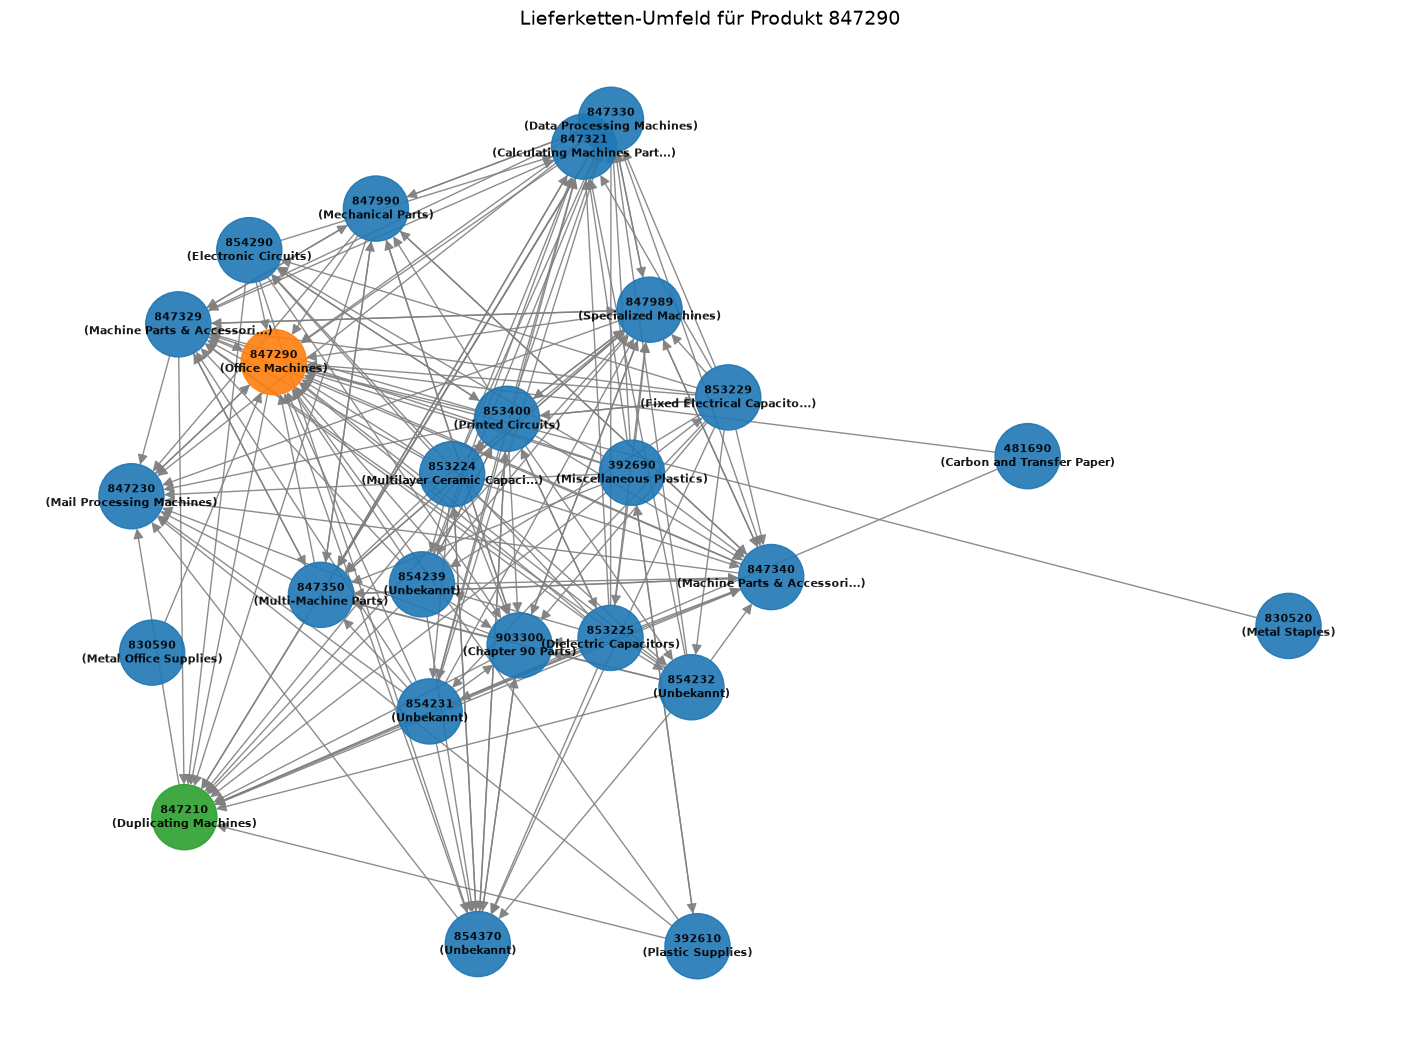

In [15]:
import matplotlib.pyplot as plt
import networkx as nx

# 1. Zielprodukt festlegen (z. B. "847290")
ziel_produkt = "847290"

# 2. Direkte Nachbarn (1 Stufe) sammeln: Inputs (predecessors) & Outputs (successors)
inputs = list(G.predecessors(ziel_produkt))
outputs = list(G.successors(ziel_produkt))

# Falls es zu viele Nachbarn sind, optional auf z. B. max. 15 begrenzen, damit der Plot lesbar bleibt:
# inputs = inputs[:15]
# outputs = outputs[:15]

# Teilgraph aus Zielprodukt + Nachbarn erstellen
relevante_knoten = [ziel_produkt] + inputs + outputs
sub_G = G.subgraph(relevante_knoten)

# 3. Beschriftungen aus dem Attribut 'short_label' zusammenbauen
labels = {}
for node in sub_G.nodes():
    label_text = sub_G.nodes[node].get("short_label", "Unbekannt")
    # Zu lange Namen umbrechen oder kürzen, damit sie sich nicht überlappen
    if len(label_text) > 25:
        label_text = label_text[:25] + "..."
    labels[node] = f"{node}\n({label_text})"

# 4. Farben vergeben: Ziel = Rot/Orange, Inputs = Blau, Outputs = Grün
farben = []
for node in sub_G.nodes():
    if node == ziel_produkt:
        farben.append("#ff7f0e")  # Orange (Fokus-Produkt)
    elif node in inputs:
        farben.append("#1f77b4")  # Blau (Vorleistungen / Upstream)
    else:
        farben.append("#2ca02c")  # Grün (Endprodukte / Downstream)

# 5. Zeichnen
plt.figure(figsize=(14, 10))
pos = nx.spring_layout(sub_G, k=1.5, seed=42)  # k steuert den Abstand zwischen den Knoten

nx.draw(
    sub_G,
    pos,
    with_labels=True,
    labels=labels,
    node_color=farben,
    node_size=2200,
    font_size=8,
    font_weight="bold",
    edge_color="gray",
    arrows=True,
    arrowsize=15,
    alpha=0.9
)

plt.title(f"Lieferketten-Umfeld für Produkt {ziel_produkt}", fontsize=14)
plt.tight_layout()
plt.show()

C:\Users\Max Tauberger\AppData\Local\Temp\ipykernel_6860\1167718179.py:61: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


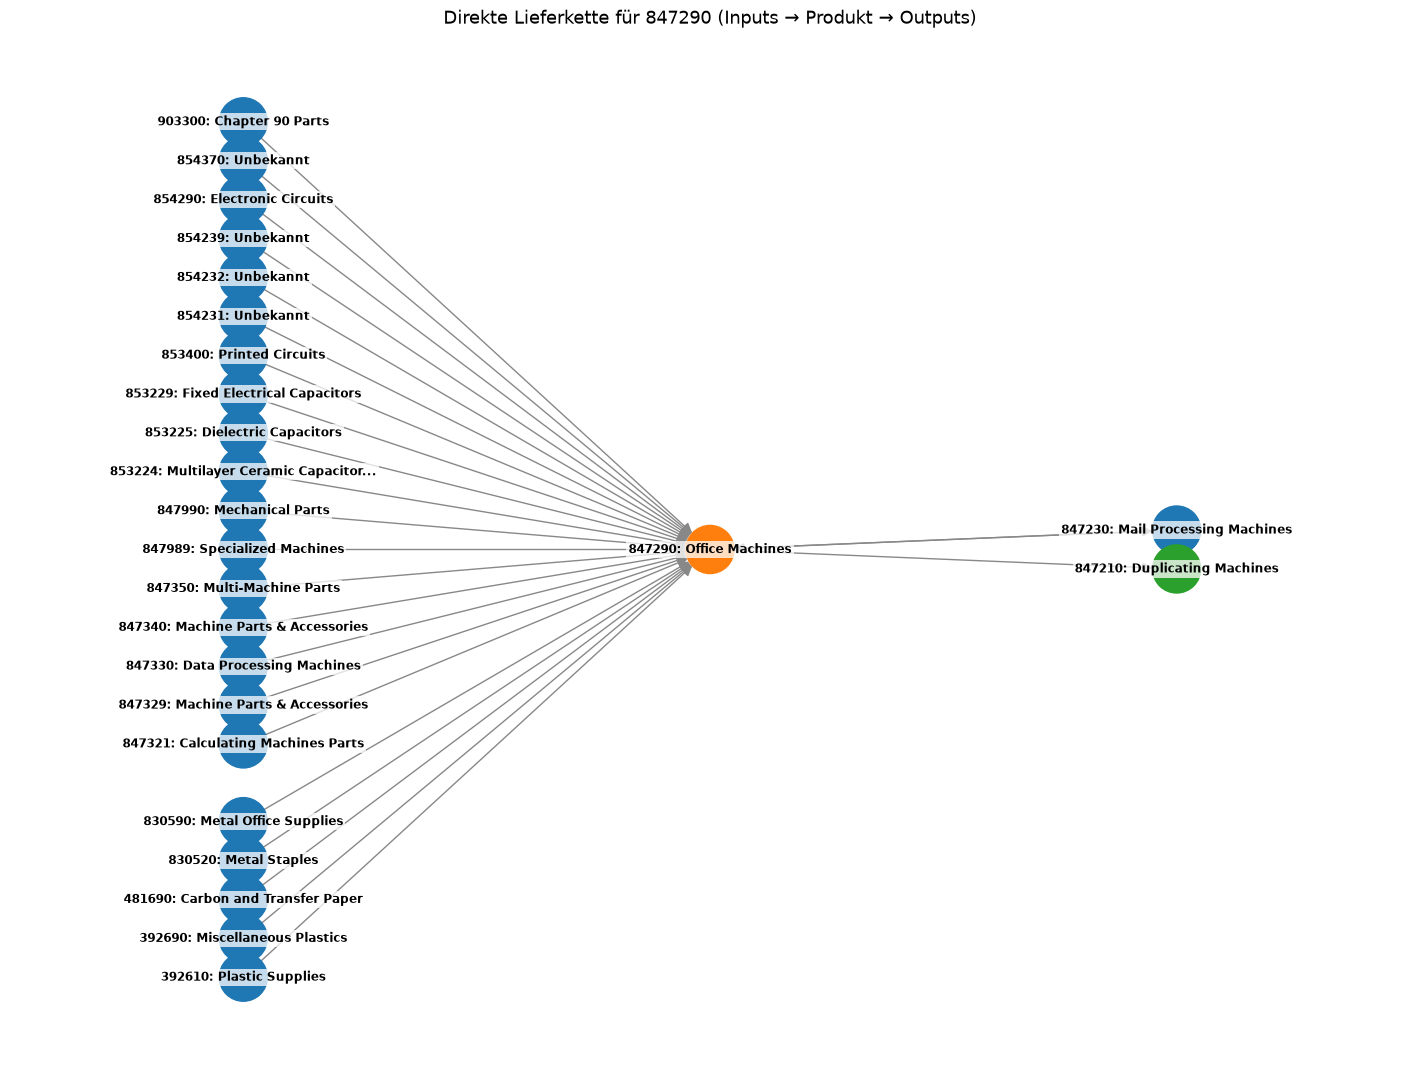

In [16]:
import matplotlib.pyplot as plt
import networkx as nx

ziel_produkt = "847290"

# 1. Direkte Inputs und Outputs holen (ohne eventuelle Selbstschleife)
inputs = sorted([n for n in G.predecessors(ziel_produkt) if n != ziel_produkt])
outputs = sorted([n for n in G.successors(ziel_produkt) if n != ziel_produkt])

# 2. Teilgraph NUR mit den direkten Kanten zum/vom Zielprodukt bauen
direkte_kanten = [(u, ziel_produkt) for u in inputs] + [(ziel_produkt, v) for v in outputs]
sub_G = nx.DiGraph(direkte_kanten)

# 3. Feste Positionen berechnen: Links (x=0) = Inputs, Mitte (x=1) = Ziel, Rechts (x=2) = Outputs
pos = {ziel_produkt: (1, 0)}

for i, node in enumerate(inputs):
    # Gleichmäßig vertikal um 0 verteilen
    y = (i - (len(inputs) - 1) / 2)
    pos[node] = (0, y)

for i, node in enumerate(outputs):
    y = (i - (len(outputs) - 1) / 2)
    pos[node] = (2, y)

# 4. Labels & Farben vorbereiten
labels = {}
farben = []
for node in sub_G.nodes():
    text = G.nodes[node].get("short_label", "Unbekannt")
    if len(text) > 28:
        text = text[:28] + "..."
    labels[node] = f"{node}: {text}"
    
    if node == ziel_produkt:
        farben.append("#ff7f0e")
    elif node in inputs:
        farben.append("#1f77b4")
    else:
        farben.append("#2ca02c")

# 5. Zeichnen
plt.figure(figsize=(14, max(8, len(inputs) * 0.45)))
nx.draw(
    sub_G,
    pos,
    with_labels=True,
    labels=labels,
    node_color=farben,
    node_size=1200,
    font_size=8.5,
    font_weight="bold",
    edge_color="#888888",
    arrows=True,
    arrowsize=15,
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1.5) # weißer Hintergrund für bessere Lesbarkeit
)

plt.xlim(-0.5, 2.5)
plt.title(f"Direkte Lieferkette für {ziel_produkt} (Inputs → Produkt → Outputs)", fontsize=13)
plt.tight_layout()
plt.show()

In [17]:
# Farben vergeben: Ziel = Orange, Beides (Input & Output) = Lila, Nur Input = Blau, Nur Output = Grün
farben = []
for node in sub_G.nodes():
    if node == ziel_produkt:
        farben.append("#ff7f0e")  # Orange (Fokus-Produkt)
    elif node in inputs and node in outputs:
        farben.append("#9467bd")  # Lila (Wechselseitig: Input & Output)
    elif node in inputs:
        farben.append("#1f77b4")  # Blau (Reiner Input / Upstream)
    else:
        farben.append("#2ca02c")  # Grün (Reiner Output / Downstream)

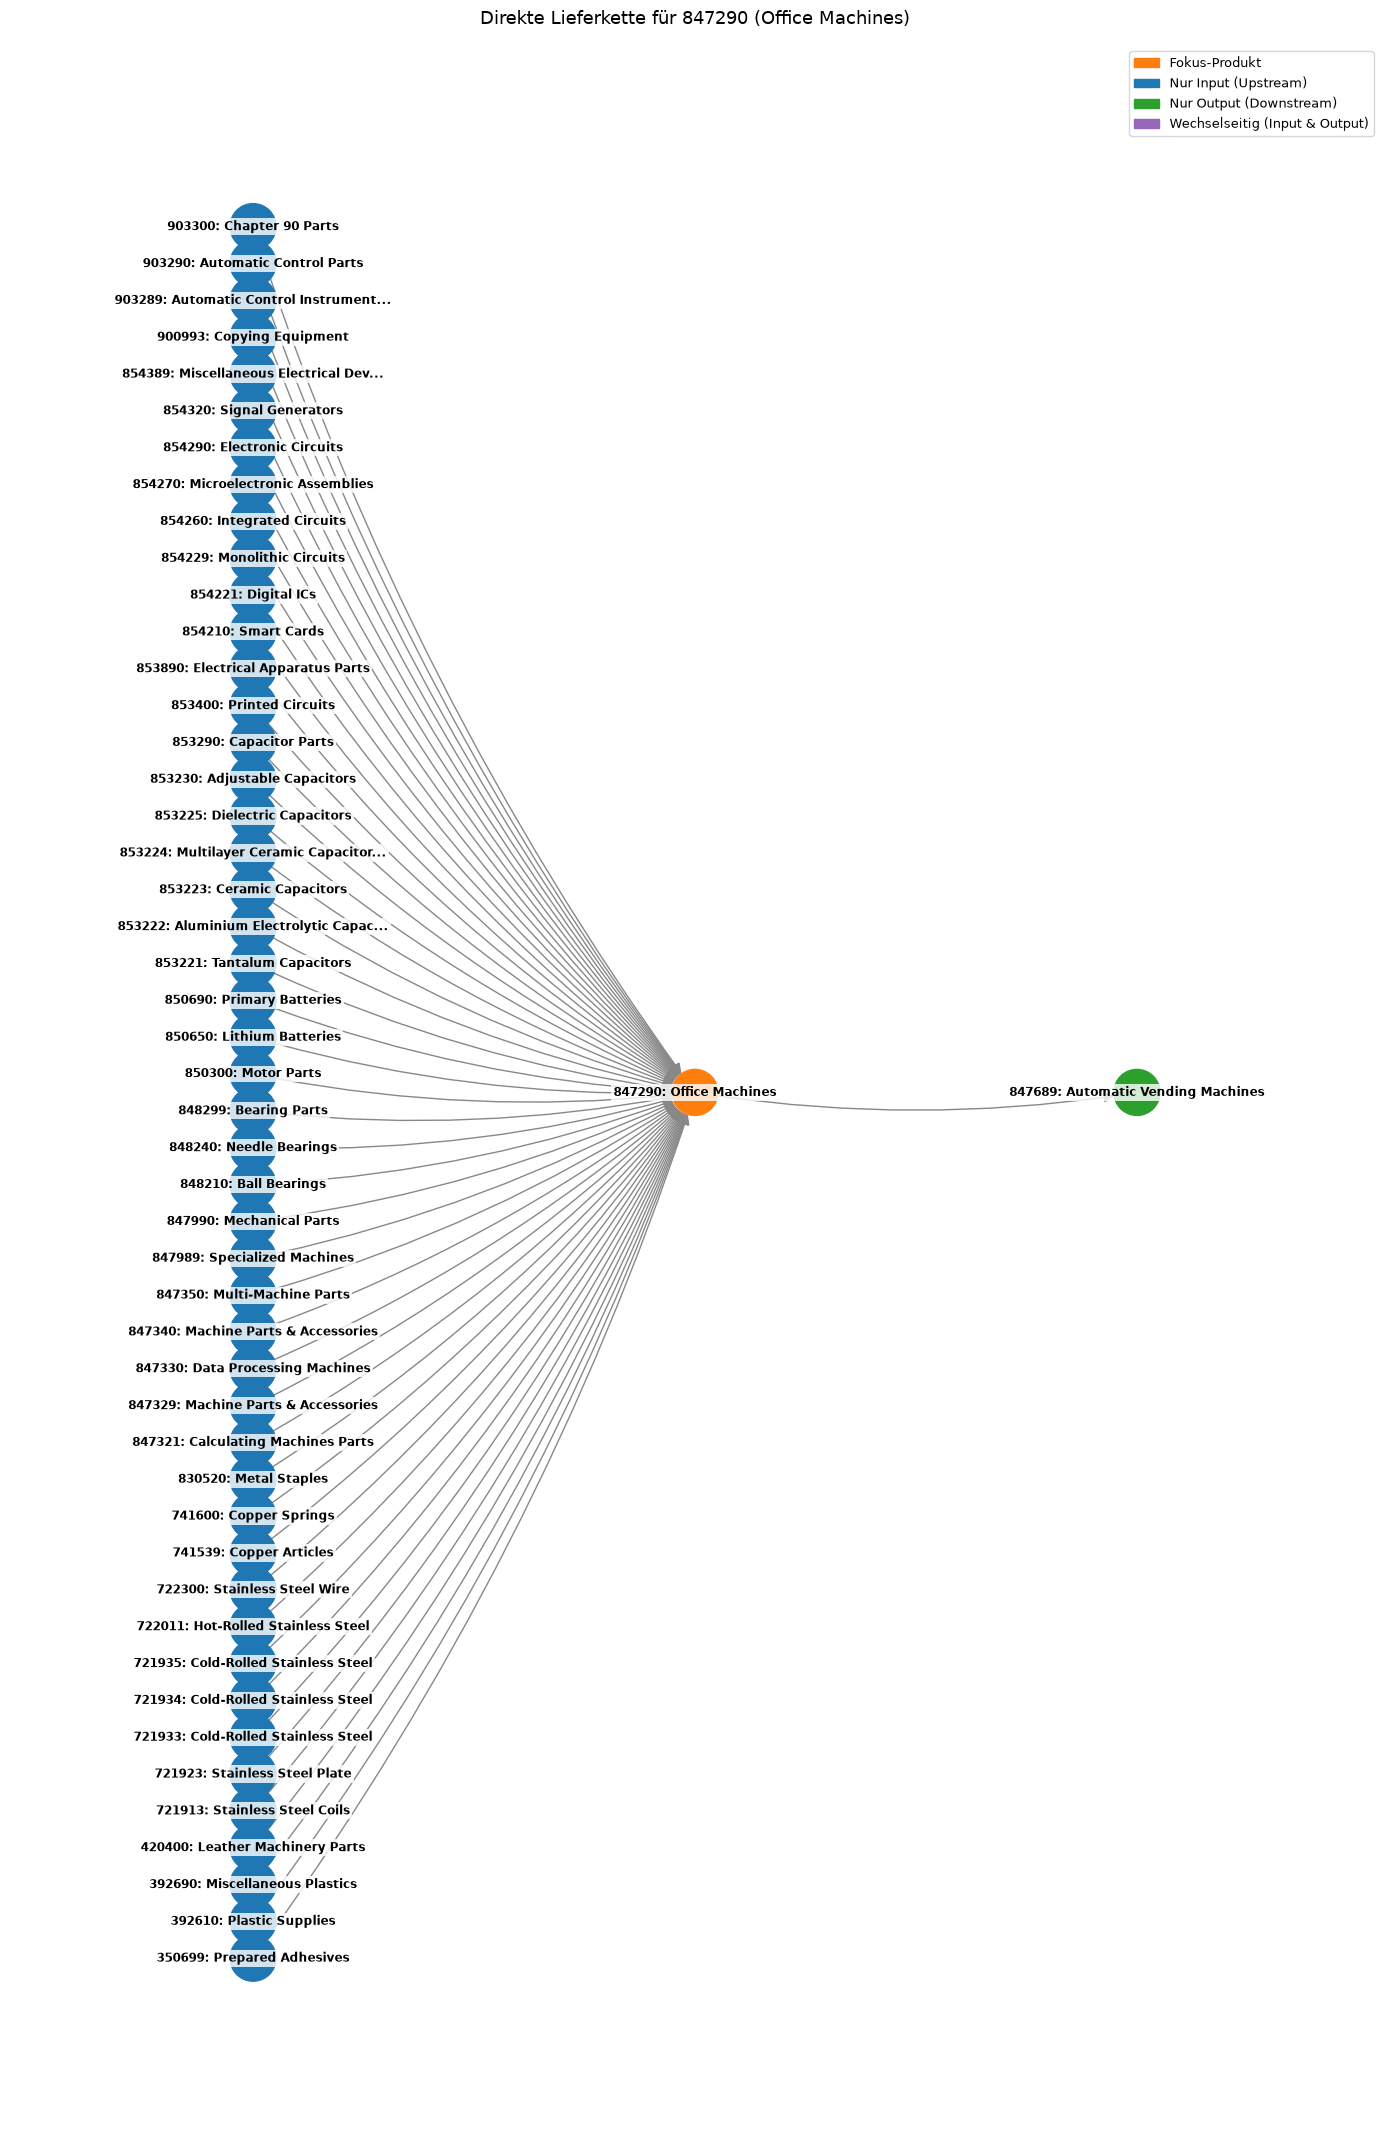

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx

# 1. Daten & Node-Liste einlesen (beides HS02, damit 100 % der Labels passen)
df = pd.read_excel(
    "data/AIPNET_Data_Pack_20241204.xlsx",
    sheet_name="2a.  6-digit HS02",
    dtype=str
)
df["hs2002_code_upstream"] = df["hs2002_code_upstream"].str.zfill(6)
df["hs2002_code_downstream"] = df["hs2002_code_downstream"].str.zfill(6)

df_nodes = pd.read_excel(
    "data/AIPNET_Data_Pack_20241204.xlsx",
    sheet_name="1a. Node List 6-digit HS02",
    dtype=str
)
df_nodes["hs_code_6d"] = df_nodes["hs_code_6d"].str.zfill(6)

# 2. Gerichteten Graphen bauen und Labels anhängen
G = nx.from_pandas_edgelist(
    df,
    source="hs2002_code_upstream",
    target="hs2002_code_downstream",
    create_using=nx.DiGraph()
)
short_dict = dict(zip(df_nodes["hs_code_6d"], df_nodes["short_label"]))
nx.set_node_attributes(G, short_dict, name="short_label")

# 3. Zielprodukt & Nachbarn filtern
ziel_produkt = "847290"

raw_inputs = set(G.predecessors(ziel_produkt)) - {ziel_produkt}
raw_outputs = set(G.successors(ziel_produkt)) - {ziel_produkt}

beides = sorted(raw_inputs & raw_outputs)       # Input UND Output (Lila)
nur_inputs = sorted(raw_inputs - raw_outputs)   # Nur Input (Blau)
nur_outputs = sorted(raw_outputs - raw_inputs)  # Nur Output (Grün)

# Teilgraph nur mit den direkten Kanten zum/vom Zielprodukt
direkte_kanten = (
    [(u, ziel_produkt) for u in raw_inputs] +
    [(ziel_produkt, v) for v in raw_outputs]
)
sub_G = nx.DiGraph(direkte_kanten)

# 4. Positionen festlegen (Links: nur Inputs, Mitte: Ziel, Rechts: Outputs + Beides)
pos = {ziel_produkt: (1, 0)}

for i, node in enumerate(nur_inputs):
    pos[node] = (0, i - (len(nur_inputs) - 1) / 2)

rechte_spalte = nur_outputs + beides
for i, node in enumerate(rechte_spalte):
    pos[node] = (2, i - (len(rechte_spalte) - 1) / 2)

# 5. Labels & Farben zuweisen
labels = {}
farben = []
for node in sub_G.nodes():
    text = G.nodes[node].get("short_label", "Unbekannt")
    if len(text) > 28:
        text = text[:28] + "..."
    labels[node] = f"{node}: {text}"

    if node == ziel_produkt:
        farben.append("#ff7f0e")  # Orange
    elif node in beides:
        farben.append("#9467bd")  # Lila
    elif node in nur_inputs:
        farben.append("#1f77b4")  # Blau
    else:
        farben.append("#2ca02c")  # Grün

# 6. Abbildung zeichnen
fig, ax = plt.subplots(figsize=(14, max(8, len(nur_inputs) * 0.45)))

nx.draw(
    sub_G,
    pos,
    ax=ax,
    with_labels=True,
    labels=labels,
    node_color=farben,
    node_size=1100,
    font_size=8.5,
    font_weight="bold",
    edge_color="#888888",
    arrows=True,
    arrowsize=15,
    connectionstyle="arc3,rad=0.08",  # leichte Krümmung, damit Hin- & Rückpfeil bei Lila beide sichtbar sind
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1.5)
)

# Legende hinzufügen
legende = [
    mpatches.Patch(color="#ff7f0e", label="Fokus-Produkt"),
    mpatches.Patch(color="#1f77b4", label="Nur Input (Upstream)"),
    mpatches.Patch(color="#2ca02c", label="Nur Output (Downstream)"),
    mpatches.Patch(color="#9467bd", label="Wechselseitig (Input & Output)")
]
ax.legend(handles=legende, loc="upper right", frameon=True, fontsize=9)

ax.set_xlim(-0.55, 2.55)
ax.set_title(f"Direkte Lieferkette für {ziel_produkt} ({G.nodes[ziel_produkt].get('short_label', '')})", fontsize=13, pad=15)
plt.tight_layout()

# 7. Abbildung als hochauflösendes Bild (PNG) und Vektorgrafik (PDF) speichern
plt.savefig(f"lieferkette_{ziel_produkt}.png", dpi=300, bbox_inches="tight")
# plt.savefig(f"lieferkette_{ziel_produkt}.pdf", bbox_inches="tight") # Optional für LaTeX/Word

plt.show()